# 02 · Preprocessing and feature extraction (Phase 5)

**Pipeline (identical for both corpora):** read → mono → resample to 16 kHz → trim edge silence → features.

| Feature set | Size | What it is |
|---|---|---|
| **eGeMAPS v02** | 88 per clip | Named voice measurements (pitch, loudness, jitter, spectral balance, timing). Interpretable. |
| **WavLM base-plus** | 13 layers × 768 per clip | Frozen pretrained speech model, averaged over time. Strong but not human-readable. |

Outputs go to `data/processed/` (git-ignored). Already-extracted files are **skipped**, so re-running is safe.
Set `REDO = True` to force re-extraction.

⏱ First run: eGeMAPS takes ~5–10 min, WavLM ~10–30 min (plus a one-time ~380 MB model download).

In [1]:
import sys, json, time
from pathlib import Path
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(PROJECT_ROOT))

import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from src.data import META_DIR
from src.audio import load_audio
from src.features import (PROCESSED_DIR, extract_egemaps, load_egemaps, load_wavlm,
                          wavlm_embed, extract_wavlm, load_wavlm_features)

REDO = False
FIG_DIR = PROJECT_ROOT / "results" / "figures"; FIG_DIR.mkdir(parents=True, exist_ok=True)
BLUE, ORANGE, INK, MUTED = "#2a78d6", "#eb6834", "#0b0b0b", "#52514e"
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.alpha": 0.25, "axes.edgecolor": MUTED, "xtick.color": MUTED,
                     "ytick.color": MUTED, "figure.dpi": 110})

meta = {c: pd.read_csv(META_DIR / f"{c}.csv") for c in ["ravdess", "cremad"]}
for c, m in meta.items():
    m["read_error"] = m["read_error"].fillna("")
    meta[c] = m[m["read_error"] == ""].reset_index(drop=True)
    print(c, len(meta[c]), "clips")

ravdess 1440 clips
cremad 7442 clips


## 1. Effect of preprocessing on clip length
This checks that trimming removes the extra leading/trailing silence in RAVDESS (Phase 3 found RAVDESS clips ~1.2 s longer).

In [2]:
t0 = time.time()
for c, m in meta.items():
    m["trimmed_s"] = [len(load_audio(p)[0]) / 16000 for p in m["path"]]
print(f"done in {time.time()-t0:.0f}s")
dur = pd.DataFrame({c: [m["duration_s"].mean(), m["trimmed_s"].mean()] for c, m in meta.items()},
                   index=["original mean (s)", "after trim mean (s)"]).round(2)
dur

done in 25s


,ravdess,cremad
original mean (s),3.7,2.54
after trim mean (s),1.9,2.39


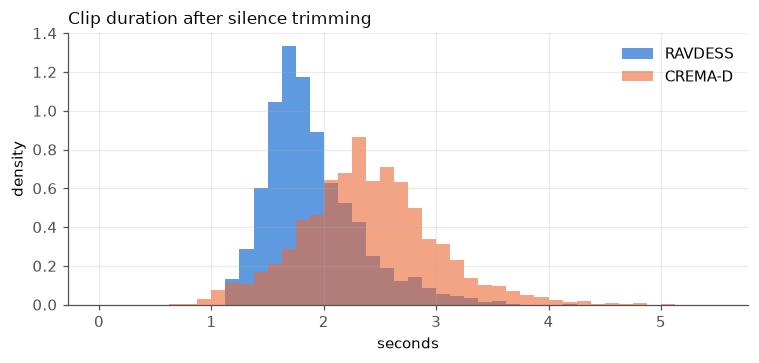

In [3]:
fig, ax = plt.subplots(figsize=(7, 3.4))
bins = np.linspace(0, 5.5, 45)
ax.hist(meta["ravdess"]["trimmed_s"], bins=bins, color=BLUE, alpha=0.75, label="RAVDESS", density=True)
ax.hist(meta["cremad"]["trimmed_s"], bins=bins, color=ORANGE, alpha=0.6, label="CREMA-D", density=True)
ax.set_title("Clip duration after silence trimming", loc="left", color=INK, fontsize=11)
ax.set_xlabel("seconds"); ax.set_ylabel("density"); ax.legend(frameon=False)
fig.tight_layout(); fig.savefig(FIG_DIR / "p5_trimmed_durations.png", bbox_inches="tight"); plt.show()

## 2. eGeMAPS (88 interpretable features)

In [4]:
eg = {}
for c, m in meta.items():
    f = PROCESSED_DIR / f"egemaps_{c}.csv"
    if f.exists() and not REDO:
        eg[c] = load_egemaps(c); print(f"{c}: loaded existing {eg[c].shape}")
    else:
        eg[c] = extract_egemaps(m, c); print(f"{c}: extracted {eg[c].shape}")

eGeMAPS ravdess:   0%|          | 0/1440 [00:00<?, ?it/s]

ravdess: extracted (1440, 88)


eGeMAPS cremad:   0%|          | 0/7442 [00:00<?, ?it/s]

cremad: extracted (7442, 88)


In [5]:
for c, df in eg.items():
    print(f"{c}: shape {df.shape}, NaN values {int(df.isna().sum().sum())}, "
          f"constant columns {int((df.std() == 0).sum())}, rows match metadata: {list(df.index) == list(meta[c]['file'])}")
eg["ravdess"].iloc[:3, :6]

ravdess: shape (1440, 88), NaN values 0, constant columns 0, rows match metadata: True
cremad: shape (7442, 88), NaN values 0, constant columns 0, rows match metadata: True


,F0semitoneFrom27.5Hz_sma3nz_amean,F0semitoneFrom27.5Hz_sma3nz_stddevNorm,F0semitoneFrom27.5Hz_sma3nz_percentile20.0,F0semitoneFrom27.5Hz_sma3nz_percentile50.0,F0semitoneFrom27.5Hz_sma3nz_percentile80.0,F0semitoneFrom27.5Hz_sma3nz_pctlrange0-2
file,,,,,,
03-01-01-01-01-01-01.wav,24.491810,0.096219,22.854485,24.000044,27.001801,4.147316
03-01-01-01-01-02-01.wav,25.012857,0.109174,22.838329,24.854345,27.782902,4.944572
03-01-01-01-02-01-01.wav,24.551188,0.095713,22.743032,23.796993,27.190125,4.447092


## 3. WavLM embeddings (13 layers × 768)
We keep **every layer** because emotion information sits mostly in the middle layers (P4, P7). In Phase 6 the layer is chosen by cross-validation **on training data only**.

In [6]:
import torch
device = "cpu"
if torch.backends.mps.is_available():
    try:   # use the Apple GPU if WavLM runs on it, otherwise fall back to CPU
        fe, model = load_wavlm(device="mps")
        _ = wavlm_embed(load_audio(meta["ravdess"]["path"][0])[0], fe, model, "mps")
        device = "mps"
    except Exception as e:
        print("MPS failed, using CPU:", str(e)[:120])
if device == "cpu":
    fe, model = load_wavlm(device="cpu")
t0 = time.time(); _ = wavlm_embed(load_audio(meta["cremad"]["path"][0])[0], fe, model, device)
print(f"device = {device}, ~{time.time()-t0:.2f} s per clip "
      f"-> estimated {(time.time()-t0)*sum(len(m) for m in meta.values())/60:.0f} min total")

W1019 09:59:05.225000 65295 .venv/lib/python3.11/site-packages/torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


preprocessor_config.json:   0%|          | 0.00/215 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/2.23k [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  378MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/248 [00:00<?, ?it/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  378MB            

model.safetensors: downloading bytes:           |  0.00B            

device = mps, ~0.22 s per clip -> estimated 32 min total


In [7]:
wl = {}
for c, m in meta.items():
    f = PROCESSED_DIR / f"wavlm_{c}.npy"
    if f.exists() and not REDO:
        wl[c], files = load_wavlm_features(c); print(f"{c}: loaded existing {wl[c].shape}")
    else:
        wl[c] = extract_wavlm(m, c, device=device, fe=fe, model=model); files = list(m["file"])
        print(f"{c}: extracted {wl[c].shape}")
    assert files == list(m["file"]), "row order mismatch"
    print(f"   finite values: {np.isfinite(wl[c].astype(np.float32)).all()}")

WavLM ravdess (mps):   0%|          | 0/1440 [00:00<?, ?it/s]

ravdess: extracted (1440, 13, 768)
   finite values: True


WavLM cremad (mps):   0%|          | 0/7442 [00:00<?, ?it/s]

cremad: extracted (7442, 13, 768)
   finite values: True


## 4. Domain-shift check (PCA)
PCA projects each clip onto the 2 directions of largest variation. If the two corpora form **separate clouds**, the features describe *which dataset* a clip came from as much as *which emotion*. That is exactly the cross-corpus problem our research question is about.

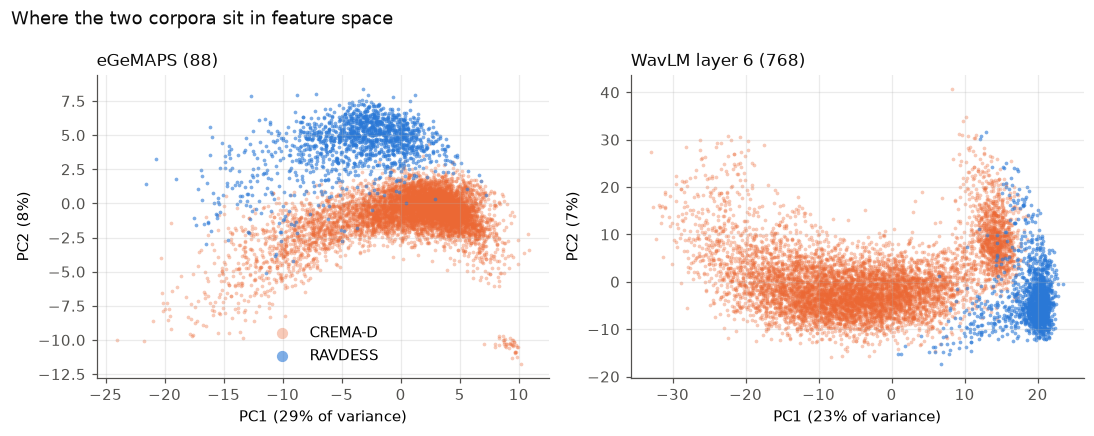

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

def pca2(Xr, Xc):
    X = StandardScaler().fit_transform(np.vstack([Xr, Xc]))
    p = PCA(n_components=2, random_state=0).fit(X)
    Z = p.transform(X)
    return Z[:len(Xr)], Z[len(Xr):], p.explained_variance_ratio_

views = {"eGeMAPS (88)": (eg["ravdess"].values, eg["cremad"].values),
         "WavLM layer 6 (768)": (wl["ravdess"][:, 6].astype(np.float32), wl["cremad"][:, 6].astype(np.float32))}
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
pca_var = {}
for ax, (name, (Xr, Xc)) in zip(axes, views.items()):
    Zr, Zc, var = pca2(Xr, Xc); pca_var[name] = [round(float(v), 3) for v in var]
    ax.scatter(Zc[:, 0], Zc[:, 1], s=6, color=ORANGE, alpha=0.35, label="CREMA-D", linewidths=0)
    ax.scatter(Zr[:, 0], Zr[:, 1], s=6, color=BLUE, alpha=0.6, label="RAVDESS", linewidths=0)
    ax.set_title(name, loc="left", color=INK, fontsize=11)
    ax.set_xlabel(f"PC1 ({var[0]:.0%} of variance)"); ax.set_ylabel(f"PC2 ({var[1]:.0%})")
axes[0].legend(frameon=False, markerscale=3)
fig.suptitle("Where the two corpora sit in feature space", x=0.01, ha="left", color=INK)
fig.tight_layout(); fig.savefig(FIG_DIR / "p5_domain_shift_pca.png", bbox_inches="tight"); plt.show()

## 5. Save summary

In [9]:
summary = {
    "preprocessing": {"target_sr": 16000, "mono": True, "trim_top_db": 30, "amplitude_normalised": False},
    "duration_mean_s": dur.to_dict(),
    "egemaps": {c: {"shape": list(df.shape), "nan": int(df.isna().sum().sum())} for c, df in eg.items()},
    "wavlm": {"model": "microsoft/wavlm-base-plus", "device": device,
              **{c: list(a.shape) for c, a in wl.items()}},
    "pca_explained_variance": pca_var,
}
out = PROJECT_ROOT / "results" / "phase5_feature_summary.json"
out.write_text(json.dumps(summary, indent=2)); print(json.dumps(summary, indent=2))

{
  "preprocessing": {
    "target_sr": 16000,
    "mono": true,
    "trim_top_db": 30,
    "amplitude_normalised": false
  },
  "duration_mean_s": {
    "ravdess": {
      "original mean (s)": 3.7,
      "after trim mean (s)": 1.9
    },
    "cremad": {
      "original mean (s)": 2.54,
      "after trim mean (s)": 2.39
    }
  },
  "egemaps": {
    "ravdess": {
      "shape": [
        1440,
        88
      ],
      "nan": 0
    },
    "cremad": {
      "shape": [
        7442,
        88
      ],
      "nan": 0
    }
  },
  "wavlm": {
    "model": "microsoft/wavlm-base-plus",
    "device": "mps",
    "ravdess": [
      1440,
      13,
      768
    ],
    "cremad": [
      7442,
      13,
      768
    ]
  },
  "pca_explained_variance": {
    "eGeMAPS (88)": [
      0.29,
      0.075
    ],
    "WavLM layer 6 (768)": [
      0.226,
      0.067
    ]
  }
}
